In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# 1. Read the whole file at once (removes the warning)
#df = pd.read_csv("../data/clean/df_final_merged.csv", low_memory=False)

# 2. Or declare the type up front
df = pd.read_csv("../data/clean/df_final_merged.csv", dtype={"variation": "string"})

In [4]:
df.head()

,Unnamed: 0,client_id,variation,visitor_id,visit_id,process_step,date_time,client_tenure_yr,client_tenure_mnth,client_age,gender,num_accts,total_balance,calls_6_mnth,logons_6_mnth
0,0,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
1,1,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
2,2,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
3,3,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
4,4,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0


In [5]:
df = df.drop(columns=["Unnamed: 0"])

In [6]:
df

,client_id,variation,visitor_id,visit_id,process_step,date_time,client_tenure_yr,client_tenure_mnth,client_age,gender,num_accts,total_balance,calls_6_mnth,logons_6_mnth
0,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
1,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
2,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
3,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
4,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
443892,9895983,<NA>,473024645_56027518531,498981662_93503779869_272484,step_3,2017-06-15 19:52:09,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
443893,9895983,<NA>,473024645_56027518531,498981662_93503779869_272484,step_2,2017-06-15 19:50:37,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
443894,9895983,<NA>,473024645_56027518531,498981662_93503779869_272484,step_1,2017-06-15 19:50:05,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
443895,9895983,<NA>,473024645_56027518531,498981662_93503779869_272484,start,2017-06-15 19:50:00,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0


In [7]:
df.duplicated().sum()

np.int64(0)

## step_1
The merged table has one row per web event, so demographics must be taken once per client

In [8]:
demo_cols = ["client_id", "variation", "client_tenure_yr", "client_tenure_mnth",
             "client_age", "gender", "num_accts", "total_balance",
             "calls_6_mnth", "logons_6_mnth"]

clients = (df[demo_cols]
           .drop_duplicates(subset="client_id")
           .reset_index(drop=True))

print(clients.shape)
print(clients["variation"].value_counts(dropna=False))

# keeping only experiment clients for the Test vs Control comparison
exp = clients.dropna(subset=["variation"]).copy()
print(exp["variation"].value_counts())

(70609, 10)
variation
Test       26968
Control    23532
<NA>       20109
Name: count, dtype: Int64
variation
Test       26968
Control    23532
Name: count, dtype: Int64


## data quality

In [9]:
print(clients.isna().sum())          # about 113 clients lack demographics
print(clients["gender"].value_counts(dropna=False))
clients[["client_age", "total_balance", "num_accts"]].describe().round(2)

client_id                 0
variation             20109
client_tenure_yr         14
client_tenure_mnth       14
client_age               15
gender                    0
num_accts                14
total_balance            14
calls_6_mnth             14
logons_6_mnth            14
dtype: int64
gender
Unspecified    24139
Male           23724
Female         22746
Name: count, dtype: int64


,client_age,total_balance,num_accts
count,70594.00,70595.00,70595.00
mean,46.45,147445.24,2.26
std,15.59,301508.71,0.53
min,14.00,13789.42,1.00
25%,32.00,37346.84,2.00
50%,47.00,63332.90,2.00
75%,59.00,137544.90,2.00
max,96.00,16320040.15,8.00


## Overall profile

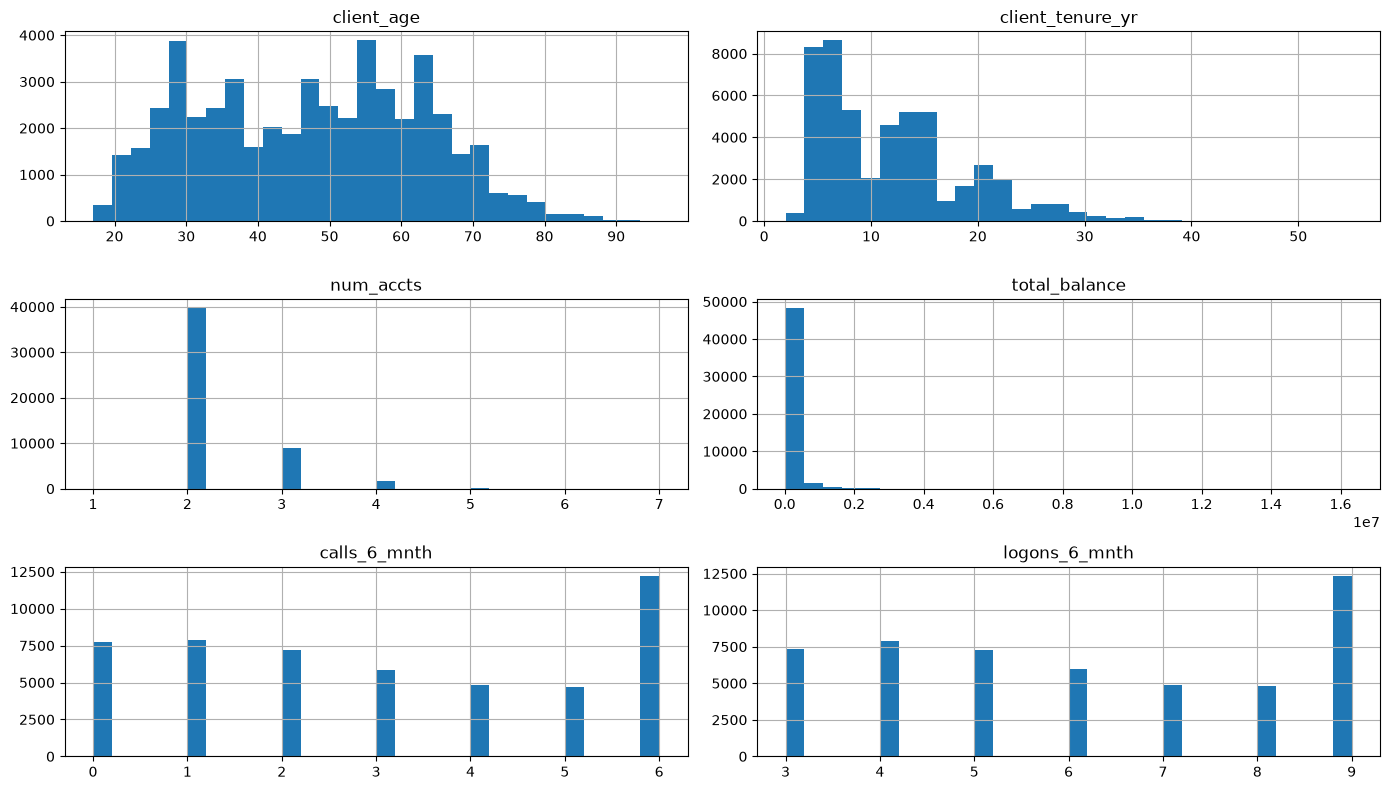

In [10]:
num_cols = ["client_age", "client_tenure_yr", "num_accts", "total_balance",
            "calls_6_mnth", "logons_6_mnth"]

exp[num_cols].describe().round(2)
exp["gender"].value_counts(normalize=True).mul(100).round(1)

exp[num_cols].hist(bins=30, figsize=(14, 8))
#exp['gender'].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

## Test vs Control (are the groups comparable?)

client_age        client_tenure_yr        num_accts         \
                mean median             mean median      mean median   
variation                                                              
Control        47.50   48.0            12.09   11.0      2.26    2.0   
Test           47.17   48.0            11.98   11.0      2.25    2.0   

          total_balance           calls_6_mnth        logons_6_mnth         
                   mean    median         mean median          mean median  
variation                                                                   
Control       150147.33  66024.18         3.13    3.0          6.17    6.0  
Test          148962.61  65468.36         3.06    3.0          6.10    6.0

gender,Female,Male,Unspecified
variation,,,
Control,32.1,33.9,34.1
Test,32.3,33.3,34.4


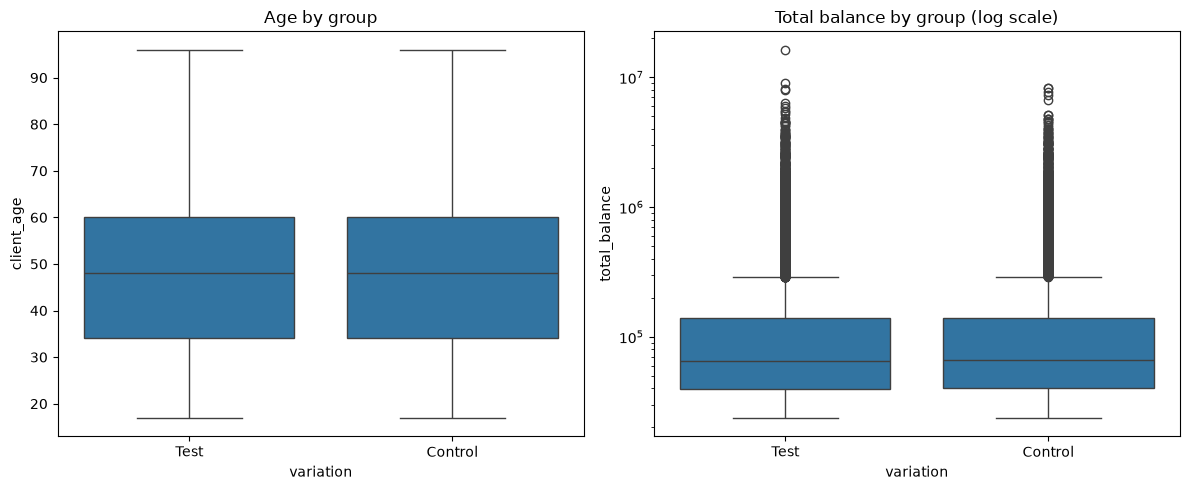

In [13]:
display(exp.groupby("variation")[num_cols].agg(["mean", "median"]).round(2))
display(pd.crosstab(exp["variation"], exp["gender"], normalize="index").mul(100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=exp, x="variation", y="client_age", ax=axes[0])
axes[0].set_title("Age by group")

sns.boxplot(data=exp[exp["total_balance"] > 0], x="variation", y="total_balance", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Total balance by group (log scale)")

plt.tight_layout()
plt.show()

In [57]:
from scipy import stats

test = exp[exp["variation"] == "Test"]
ctrl = exp[exp["variation"] == "Control"]

for c in num_cols:
    _, p = stats.mannwhitneyu(test[c].dropna(), ctrl[c].dropna())
    print(c, round(p, 4))

client_age 0.0154
client_tenure_yr 0.0869
num_accts 0.0302
total_balance 0.1486
calls_6_mnth 0.0005
logons_6_mnth 0.0008


## Segments

In [58]:
exp["age_group"] = pd.cut(exp["client_age"], [0, 30, 45, 60, 120],
                          labels=["<30", "30-44", "45-59", "60+"])
exp["balance_group"] = pd.qcut(exp["total_balance"], 4,
                               labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

exp.groupby("age_group", observed=True)[["total_balance", "num_accts", "logons_6_mnth"]].median().round(2)
pd.crosstab(exp["age_group"], exp["variation"], normalize="columns").mul(100).round(1)

variation,Control,Test
age_group,,
<30,18.9,19.3
30-44,25.9,26.4
45-59,32.2,32.0
60+,23.1,22.4


## Relationships between the variables

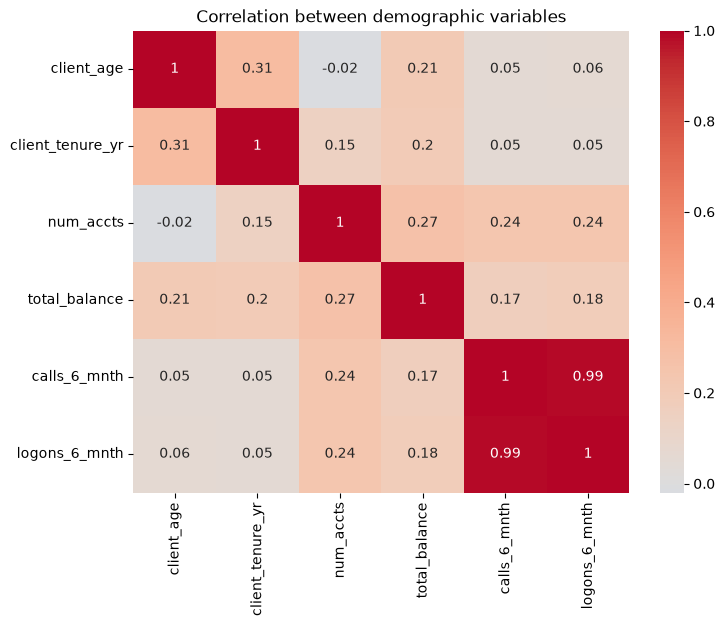

In [14]:
plt.close("all")

# 1. Correlation heatmap (no log scale here)
plt.figure(figsize=(8, 6))
sns.heatmap(exp[num_cols].corr().round(2), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation between demographic variables")
plt.show()



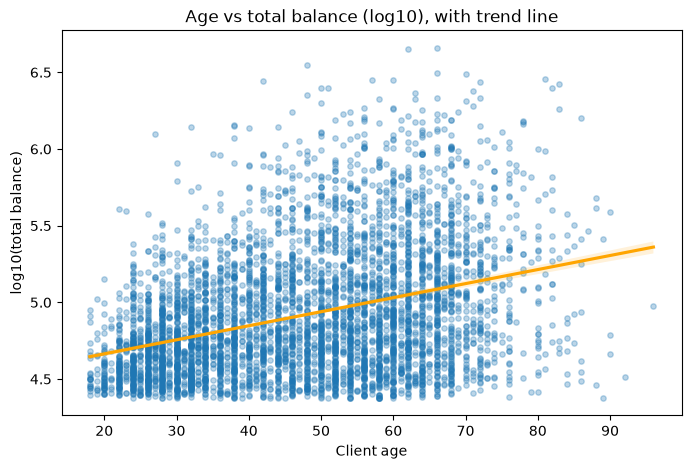

In [17]:
import numpy as np
plot_df = exp[exp["total_balance"] > 0].sample(5000, random_state=1).copy()
plot_df["log_balance"] = np.log10(plot_df["total_balance"])

plt.figure(figsize=(8, 5))
sns.regplot(
    data=plot_df, x="client_age", y="log_balance",
    scatter_kws={"alpha": 0.3, "s": 15},
    line_kws={"color": "orange"},
)
plt.ylabel("log10(total balance)")
plt.xlabel("Client age")
plt.title("Age vs total balance (log10), with trend line")
plt.show()

What to write up
Size: how many clients are in each group, and how many were excluded for having no label.
Typical client: median age, tenure, accounts and balance, plus the gender mix.
Data issues: about 113 clients with missing demographics, plus any odd values, and what you did about them.
Fairness: whether Test and Control look similar. If not, a completion-rate gap could reflect who was in each group rather than the website.

In [45]:
import numpy as np
steps = ["start", "step_1", "step_2", "step_3", "confirm"]

ev = df.dropna(subset=["variation"])      # experiment clients only

counts = (pd.crosstab(ev["client_id"], ev["process_step"])
            .reindex(columns=steps, fill_value=0))    # rows = clients, columns = step counts
counts

process_step,start,step_1,step_2,step_3,confirm
client_id,,,,,
555,1,1,1,1,1
647,1,1,1,1,1
934,4,0,0,0,0
1028,1,5,2,1,0
1104,2,0,0,0,0
...,...,...,...,...,...
9999150,2,1,0,0,0
9999400,1,1,1,1,1
9999626,1,1,0,0,0


In [ ]:
# Every step exactly once
client_counts["perfect_completed"] = (client_counts[steps] == 1).all(axis=1)
# Every step at least once
client_counts["completed"] = (client_counts[steps] >= 1).all(axis=1)
# Missing at least one step
client_counts["not_completed"] = ~client_counts["completed"]
# Completed, but with repeats/errors (except perfect_completed)
client_counts["error_completed"] = client_counts["completed"] & ~client_counts["perfect_completed"]

In [59]:
has_all   = (counts > 0).all(axis=1)                  # all 5 steps,  
perfect   = (counts == 1).all(axis=1)                 # all 5 steps, each exactly once
repeated  = has_all & (counts > 1).any(axis=1)        # all 5 steps, at least one repeated

status = pd.DataFrame({
    "perfect": perfect,
    "error_completion": repeated,
    "completed": has_all,                             # perfect + error completion
    "not_completed": ~has_all,
    "reached_confirm": counts["confirm"] > 0,
})

clients = (ev[["client_id", "variation", "client_age"]]
           .drop_duplicates("client_id")
           .merge(status.reset_index(), on="client_id"))
clients

,client_id,variation,client_age,perfect,error_completion,completed,not_completed,reached_confirm
0,9988021,Test,79.0,False,False,False,True,False
1,8320017,Test,34.0,True,False,True,False,True
2,4033851,Control,64.0,False,True,True,False,True
3,1982004,Test,44.0,True,False,True,False,True
4,9294070,Control,29.0,False,False,False,True,False
...,...,...,...,...,...,...,...,...
50495,393005,Control,52.0,False,True,True,False,True
50496,2908510,Control,34.0,False,False,False,True,False
50497,7230446,Test,62.0,False,False,False,True,False
50498,5230357,Test,30.0,True,False,True,False,True


In [39]:
kpi = (clients.groupby("variation")[["perfect", "completed", "error_completion",
                                     "not_completed", "reached_confirm"]]
              .mean().mul(100).round(2).T)
kpi["diff_pp"] = (kpi["Test"] - kpi["Control"]).round(2)
kpi

variation,Control,Test,diff_pp
perfect,31.28,30.68,-0.60
completed,64.62,68.00,3.38
error_completion,33.34,37.32,3.98
not_completed,35.38,32.00,-3.38
reached_confirm,65.59,69.29,3.70


In [40]:
clients["age_group"] = pd.cut(clients["client_age"], [0, 30, 45, 60, 120],
                              labels=["<30", "30-44", "45-59", "60+"])

kpis = ["perfect", "completed", "error_completion", "not_completed"]

age_kpi = (clients.groupby(["variation", "age_group"], observed=True)[kpis]
                  .mean().mul(100).round(2))
age_kpi

perfect  completed  error_completion  not_completed
variation age_group                                                     
Control   <30          34.31      67.09             32.78          32.91
          30-44        35.34      65.27             29.93          34.73
          45-59        31.37      66.94             35.57          33.06
          60+          24.12      58.59             34.48          41.41
Test      <30          36.70      73.22             36.53          26.78
          30-44        34.77      68.10             33.33          31.90
          45-59        28.55      68.86             40.31          31.14
          60+          23.71      62.13             38.42          37.87

In [41]:
t = (clients.groupby(["age_group", "variation"], observed=True)["completed"]
            .mean().unstack().mul(100).round(2))
t["diff_pp"] = (t["Test"] - t["Control"]).round(2)
t

variation,Control,Test,diff_pp
age_group,,,
<30,67.09,73.22,6.13
30-44,65.27,68.10,2.83
45-59,66.94,68.86,1.92
60+,58.59,62.13,3.54


In [42]:
from scipy.stats import chi2_contingency
import statsmodels.formula.api as smf

# Does the completion rate differ across age groups, within each group?
for g, d in clients.groupby("variation"):
    chi2, p, *_ = chi2_contingency(pd.crosstab(d["age_group"], d["completed"]))
    print(g, "age vs completion, p =", round(p, 4))

# Effect of the new site after controlling for age
clients["test"] = (clients["variation"] == "Test").astype(int)
clients["completed_int"] = clients["completed"].astype(int)
m = smf.logit("completed_int ~ test * client_age", data=clients.dropna(subset=["client_age"])).fit()
print(m.summary())

Control age vs completion, p = 0.0
Test age vs completion, p = 0.0
Optimization terminated successfully.
         Current function value: 0.635362
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          completed_int   No. Observations:                50487
Model:                          Logit   Df Residuals:                    50483
Method:                           MLE   Df Model:                            3
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                0.004473
Time:                        14:34:55   Log-Likelihood:                -32078.
converged:                       True   LL-Null:                       -32222.
Covariance Type:            nonrobust   LLR p-value:                 3.442e-62
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.9715     

In [43]:
from scipy.stats import chi2_contingency
import statsmodels.formula.api as smf

# Does the completion rate differ across age groups, within each group?
for g, d in clients.groupby("variation"):
    chi2, p, *_ = chi2_contingency(pd.crosstab(d["age_group"], d["completed"]))
    print(g, "age vs completion, p =", round(p, 4))

# Effect of the new site after controlling for age
clients["test"] = (clients["variation"] == "Test").astype(int)
clients["completed_int"] = clients["completed"].astype(int)
m = smf.logit("completed_int ~ test * client_age", data=clients.dropna(subset=["client_age"])).fit()
print(m.summary())

Control age vs completion, p = 0.0
Test age vs completion, p = 0.0
Optimization terminated successfully.
         Current function value: 0.635362
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          completed_int   No. Observations:                50487
Model:                          Logit   Df Residuals:                    50483
Method:                           MLE   Df Model:                            3
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                0.004473
Time:                        14:35:02   Log-Likelihood:                -32078.
converged:                       True   LL-Null:                       -32222.
Covariance Type:            nonrobust   LLR p-value:                 3.442e-62
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.9715     

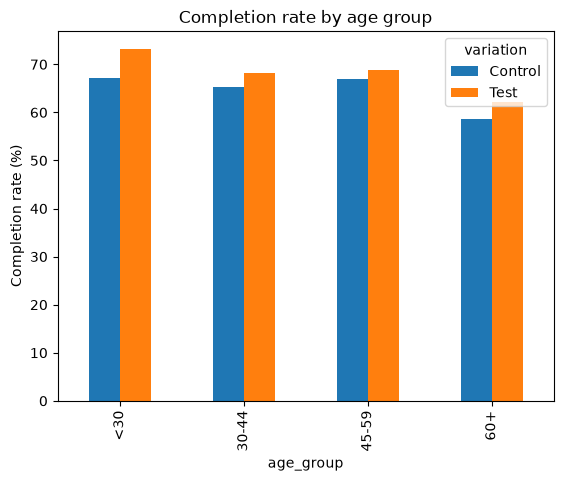

In [44]:
import matplotlib.pyplot as plt

(clients.groupby(["age_group", "variation"], observed=True)["completed"]
        .mean().unstack().mul(100)
        .plot(kind="bar", ylabel="Completion rate (%)", title="Completion rate by age group"))
plt.show()